# Movies & TV Shows Analysis

How are genre, production country, and budget related to rating and commercial return?

This notebook reads the local SQLite database built by `db/main.py`, creates analysis views, and walks through five focused questions. Profit is `revenue - budget`. ROI is `profit / budget` and is only defined when both fields are present and budget is positive.

In [1]:
from pathlib import Path
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

HERE = Path.cwd().resolve()
ROOT = HERE if (HERE / 'db' / 'database').exists() else HERE.parent
DB_PATH = ROOT / 'db' / 'database'
VIEWS_SQL = ROOT / 'db' / 'sql' / 'views.sql'
ANALYSIS_DIR = ROOT / 'db' / 'sql' / 'analysis'
if not DB_PATH.exists():
    raise FileNotFoundError(f'SQLite database not found at {DB_PATH}. Run db/main.py first.')

conn = sqlite3.connect(DB_PATH)
conn.executescript(VIEWS_SQL.read_text())


def read_sql_file(name: str) -> pd.DataFrame:
    return pd.read_sql_query((ANALYSIS_DIR / name).read_text(), conn)


try:
    plt.style.use('seaborn-v0_8-whitegrid')
except OSError:
    plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['axes.titlesize'] = 12

## 1. Data coverage: ratings and financials

Before comparing ROI or box office, check how complete the fields are. Missing budget or revenue shrinks every financial conclusion.

,movie_count,missing_financials,missing_financials_pct,missing_rating,missing_rating_pct,avg_rating
0,480,97,20.2,1,0.2,7.04


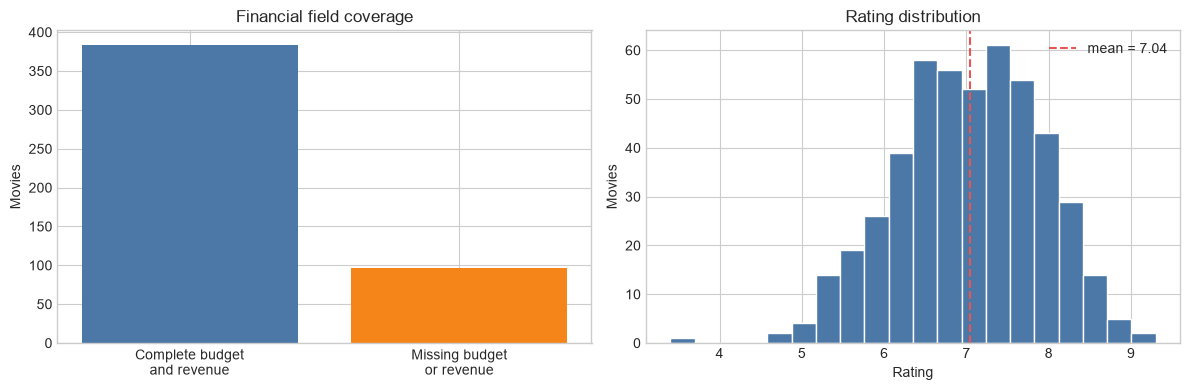

In [2]:
coverage = read_sql_file('rating_coverage.sql')
display(coverage)

ratings = pd.read_sql_query(
    'SELECT rating FROM Movies WHERE rating IS NOT NULL',
    conn,
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

missing = coverage.iloc[0]
axes[0].bar(
    ['Complete budget\nand revenue', 'Missing budget\nor revenue'],
    [missing.movie_count - missing.missing_financials, missing.missing_financials],
    color=['#4C78A8', '#F58518'],
)
axes[0].set_ylabel('Movies')
axes[0].set_title('Financial field coverage')

axes[1].hist(ratings['rating'], bins=20, color='#4C78A8', edgecolor='white')
axes[1].axvline(ratings['rating'].mean(), color='#E45756', linestyle='--', label=f"mean = {ratings['rating'].mean():.2f}")
axes[1].set_xlabel('Rating')
axes[1].set_ylabel('Movies')
axes[1].set_title('Rating distribution')
axes[1].legend()

plt.tight_layout()
plt.show()

**Takeaway:** About one fifth of movies lack budget or revenue, so ROI and profit charts only describe the financially complete subset. Ratings themselves are nearly complete and center around 7.

## 2. Rating vs box-office revenue

Do higher-rated movies earn more? Plot individual titles with a log-scaled revenue axis, then summarize averages by rating.

Pearson correlation (rating vs log10 revenue): 0.066


,rating,avg_revenue,avg_profit
32,8.2,5.630846e+08,489784612.0
33,8.3,6.512370e+08,555237004.0
34,8.4,1.146250e+09,946750233.0
35,8.5,4.128056e+08,336424074.0
36,8.6,3.843211e+08,319321142.0
37,8.7,6.750200e+08,510020017.0
38,8.8,7.517391e+08,644239082.0
39,8.9,5.427295e+08,492229543.0
40,9.2,2.450664e+08,239066411.0
41,9.3,5.850000e+07,33500000.0


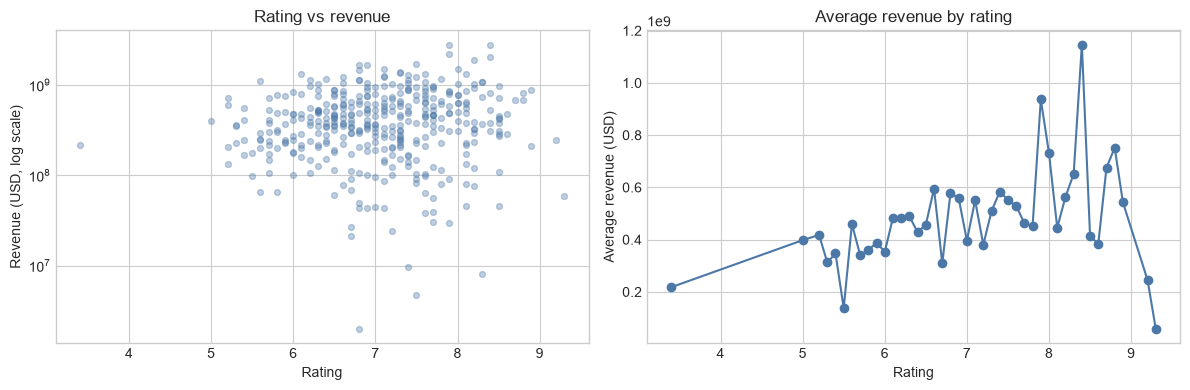

In [3]:
scatter = pd.read_sql_query(
    '''
    SELECT rating, revenue, profit
    FROM movie_financials
    WHERE rating IS NOT NULL AND revenue IS NOT NULL AND revenue > 0
    ''',
    conn,
)
by_rating = read_sql_file('rating_vs_revenue.sql')

corr = scatter['rating'].corr(np.log10(scatter['revenue']))
print(f'Pearson correlation (rating vs log10 revenue): {corr:.3f}')
display(by_rating.tail(10))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(scatter['rating'], scatter['revenue'], alpha=0.35, s=18, color='#4C78A8')
axes[0].set_yscale('log')
axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Revenue (USD, log scale)')
axes[0].set_title('Rating vs revenue')

axes[1].plot(by_rating['rating'], by_rating['avg_revenue'], marker='o', color='#4C78A8')
axes[1].set_xlabel('Rating')
axes[1].set_ylabel('Average revenue (USD)')
axes[1].set_title('Average revenue by rating')
axes[1].ticklabel_format(style='scientific', axis='y', scilimits=(9, 9))

plt.tight_layout()
plt.show()

**Takeaway:** The link between rating and revenue is weak. Mid-to-high ratings still span several orders of magnitude in box office, so a strong score alone does not predict commercial scale.

## 3. ROI by genre

Compare return on investment across genres with at least five movies that have both budget and revenue. Mean ROI can be pulled by outliers; median ROI is more stable.

,movie_count,avg_roi,median_roi,avg_profit
genre,,,,
Romance,36,5.92,4.58,3.699170e+08
Horror,13,12.95,4.27,1.826058e+08
Musical,27,5.20,3.98,4.523319e+08
Music,11,4.69,3.86,2.662856e+08
Mystery,31,6.22,3.60,3.807651e+08
Family,146,4.78,3.40,4.238925e+08
Animation,112,4.81,3.35,4.271272e+08
Comedy,197,4.95,3.35,3.557306e+08
Crime,60,5.04,3.31,2.904067e+08


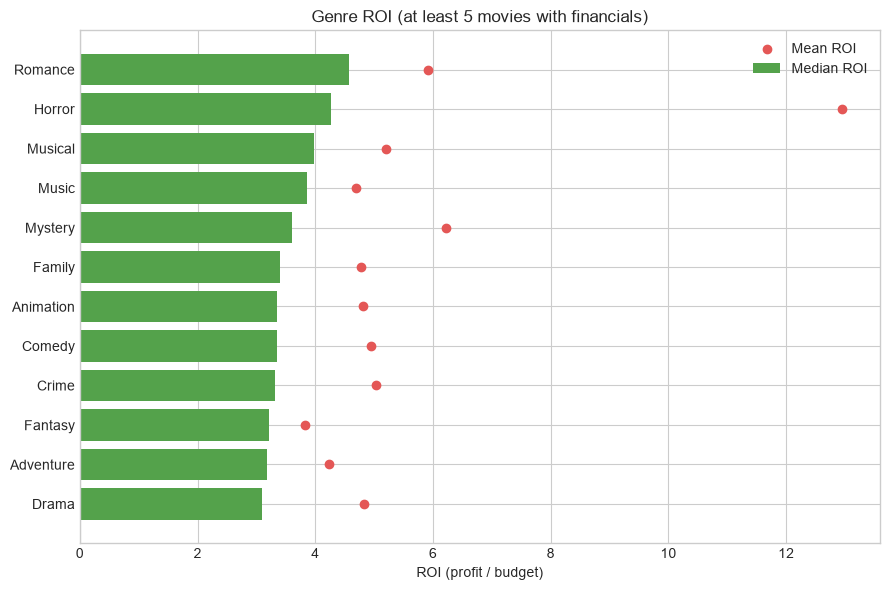

In [4]:
roi_detail = pd.read_sql_query(
    '''
    SELECT G.name AS genre, MF.roi, MF.profit, MF.budget
    FROM movie_financials MF
    JOIN ContentGenres CG ON MF.id = CG.movie_id
    JOIN Genres G ON CG.genre_id = G.id
    WHERE MF.roi IS NOT NULL
    ''',
    conn,
)

roi_by_genre = (
    roi_detail.groupby('genre')
    .agg(
        movie_count=('roi', 'count'),
        avg_roi=('roi', 'mean'),
        median_roi=('roi', 'median'),
        avg_profit=('profit', 'mean'),
    )
    .query('movie_count >= 5')
    .sort_values('median_roi', ascending=False)
)
display(roi_by_genre.round(2))

plot_df = roi_by_genre.head(12).sort_values('median_roi')
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(plot_df.index, plot_df['median_roi'], color='#54A24B', label='Median ROI')
ax.scatter(plot_df['avg_roi'], plot_df.index, color='#E45756', zorder=3, label='Mean ROI')
ax.set_xlabel('ROI (profit / budget)')
ax.set_title('Genre ROI (at least 5 movies with financials)')
ax.legend()
plt.tight_layout()
plt.show()

**Takeaway:** Romance, horror, and musical titles show the strongest median returns in this sample. Mean ROI for horror is much higher than its median, which points to a few extreme hits. Large adventure and sci-fi titles often make more absolute profit while returning less per dollar of budget.

## 4. Genre rating by production country

For the countries with the most movie titles, compare average ratings across genres. Cells need at least three movies so sparse combinations do not dominate the heatmap.

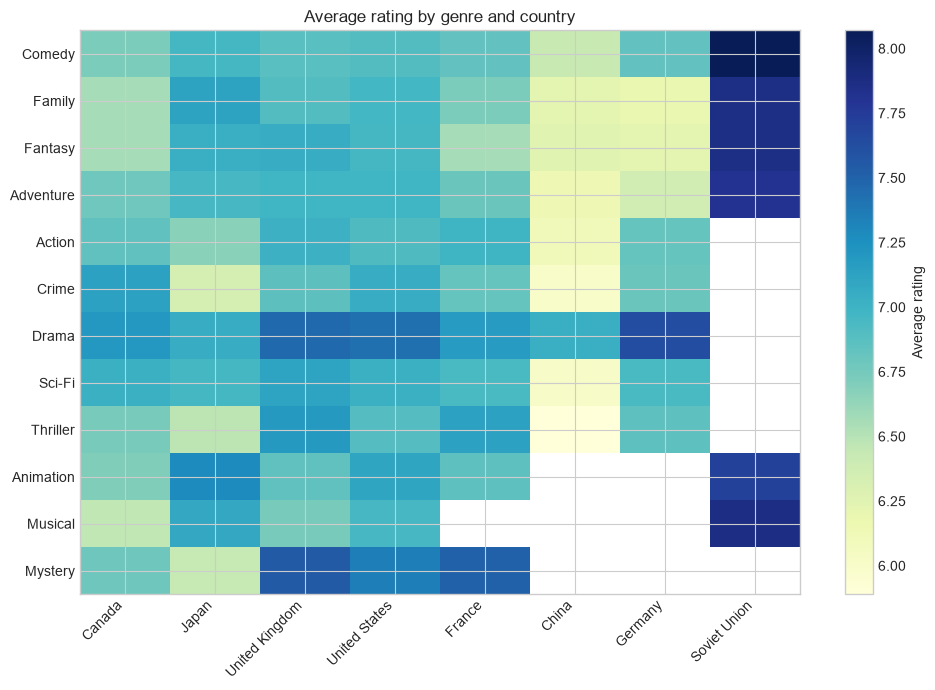

,country,genre,movie_count,avg_rating
61,Soviet Union,Comedy,12,8.07
64,Soviet Union,Musical,3,7.87
63,Soviet Union,Fantasy,5,7.86
62,Soviet Union,Family,22,7.86
59,Soviet Union,Adventure,14,7.81
60,Soviet Union,Animation,35,7.71
65,Soviet Union,Short,33,7.71
44,Germany,War,4,7.68
39,Germany,Drama,9,7.63
87,United States,Biography,11,7.55


In [5]:
genre_country = read_sql_file('genre_country_rating.sql')
pivot = genre_country.pivot(index='genre', columns='country', values='avg_rating')

# Keep genres present in several countries for a readable heatmap.
pivot = pivot.loc[pivot.notna().sum(axis=1).sort_values(ascending=False).head(12).index]
pivot = pivot[pivot.notna().sum().sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(pivot.values, aspect='auto', cmap='YlGnBu')
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns, rotation=45, ha='right')
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)
ax.set_title('Average rating by genre and country')
fig.colorbar(im, ax=ax, label='Average rating')
plt.tight_layout()
plt.show()

display(genre_country.sort_values('avg_rating', ascending=False).head(10))

**Takeaway:** The United States dominates the sample by title count, so country comparisons are uneven. Within the denser cells, average ratings still differ by genre and country rather than following one global ranking.

## 5. Box office over time

Aggregate total reported revenue by release year and highlight the year with the largest year-over-year increase.

,year,revenue_change
0,2017,6023551252


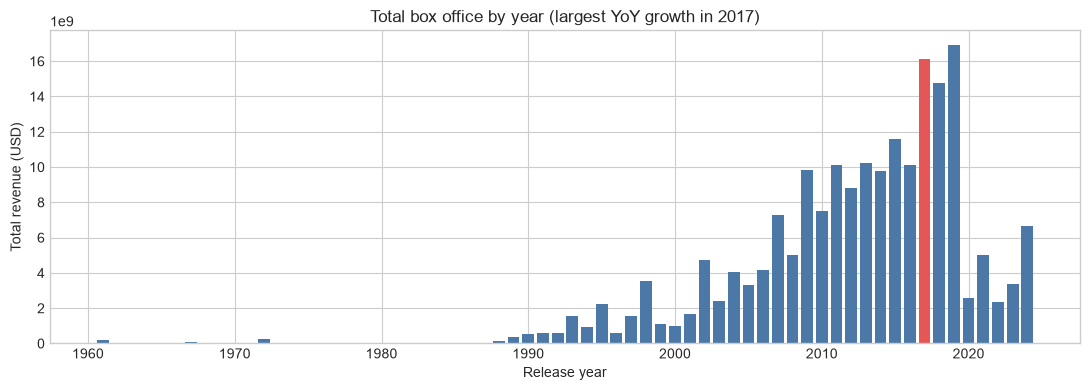

In [6]:
yearly = pd.read_sql_query(
    '''
    SELECT release_year AS year,
           SUM(revenue) AS total_revenue,
           COUNT(*) AS movie_count
    FROM movie_financials
    WHERE revenue IS NOT NULL AND release_year IS NOT NULL
    GROUP BY release_year
    ORDER BY release_year
    ''',
    conn,
)
growth = read_sql_file('year_with_largest_revenue_growth.sql')
display(growth)

peak_year = int(growth.iloc[0]['year'])
colors = ['#E45756' if y == peak_year else '#4C78A8' for y in yearly['year']]

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(yearly['year'], yearly['total_revenue'], color=colors)
ax.set_xlabel('Release year')
ax.set_ylabel('Total revenue (USD)')
ax.set_title(f'Total box office by year (largest YoY growth in {peak_year})')
ax.ticklabel_format(style='scientific', axis='y', scilimits=(9, 9))
plt.tight_layout()
plt.show()

**Takeaway:** Aggregate revenue climbs through the 2010s and jumps most sharply into 2017 in this dataset. Later years look quieter, which can reflect both market shocks and incomplete coverage of recent releases in the CSV sample.

## Summary

1. Financial fields are missing for roughly 20% of movies, so ROI analysis is conditional on complete budgets and revenues.
2. Rating and revenue are only weakly related; high scores do not guarantee large box office.
3. Median ROI favors smaller-budget genres such as romance and horror more than big adventure/sci-fi titles.
4. Country and genre ratings vary, but the sample is heavily skewed toward US productions.
5. The largest year-over-year box-office increase in the sample is 2017.

Currency caveat: non-USD budgets and revenues were converted with a current exchange-rate API at import time, not with historical rates for each release year.

In [7]:
conn.close()